# STLRocket pipeline, end to end

One dataset, one seed, every step of the method:

1. data and standardization
2. bank of STL formulae, centred with class-balanced weights
3. LASSO classifier: **balanced accuracy on train and test**
4. the instance explanation of one prediction, step by step
5. **explanations in the units of the original series**: the thresholds read directly on the raw data
6. instance explanations of the whole test set: **precision, recall and size**
7. global explanations: **precision, recall, F1 and size of each class, and how they separate the classes**

All metrics are with respect to the predictions of the classifier and computed on the explanations as built (before simplification), as in the paper. Sizes are the numbers of nodes of the simplified STL formulae, which is what a reader sees.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "local_experiments" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aeon.datasets import load_classification
from sklearn.metrics import balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

from plot_comparison import INK, INK_2, GRID, style_axis      # paper style (also sets its rcParams)
from case_study import CLASS_COLORS
from stlrocket.config import ExperimentConfig
from stlrocket.data import load_dataset, _fill_missing
from stlrocket.features import build_formula_bank, eval_robustness
from stlrocket.classifier import train_classifier
from stlrocket.formula_sampler import F0
from stlrocket import instance_rules as ir
from stlrocket.pretty import DATASET_INFO, to_original_units, atom_spans, atom_threshold, nnf

DATASET, SEED = "Epilepsy", 0     # also works with "BasicMotions" (DATASET_INFO has their variable names)
pd.set_option("display.max_colwidth", 200)
OTHER = "#b3b3b3"                 # series of the other classes
plt.rcParams.update({"font.family": "sans-serif", "mathtext.fontset": "dejavusans"})   # paper font lacks <, >, _ in text

## 1. Data

`load_dataset` fills missing values and standardizes every variable with its mean $m_v$ and std $s_v$ over all train series and time steps; with `return_stats=True` it also returns them. The original series are loaded separately, filled in the same way.

In [2]:
X_tr, y_tr, X_te, y_te, mean, std = load_dataset(DATASET, return_stats=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    X_raw = {s: _fill_missing(load_classification(DATASET, split=s.upper())[0].astype(np.float32)) for s in ("train", "test")}
info = DATASET_INFO[DATASET]
T = X_tr.shape[2]
t_sec = np.arange(T) / info.hz
print(f"train {X_tr.shape}, test {X_te.shape}  (series, variables, time steps), sampled at {info.hz} Hz")
print("classes:", {str(c): int(n) for c, n in zip(*np.unique(y_tr, return_counts=True))})
pd.DataFrame({"mean m_v": mean, "std s_v": std}, index=info.var_names).round(3)

train (137, 3, 206), test (138, 3, 206)  (series, variables, time steps), sampled at 16.0 Hz
classes: {'epilepsy': 34, 'running': 36, 'sawing': 30, 'walking': 37}


,mean m_v,std s_v
acc_x,0.070,0.968
acc_y,-0.290,1.020
acc_z,-0.102,0.512


## 2. Bank of STL formulae

$M = 10^4$ formulae of depth at most 2, without until. Each formula is shifted with the robustness shift property so that its robustness has zero **class-balanced** mean on train, and its feature is that robustness divided by its class-balanced std.

In [3]:
cfg = ExperimentConfig(
    dataset=DATASET, n_formulas=10_000, depth_max=2, until_weight=0.0, cv=3, cut_point=1.0,
    fit_intercept=False, n_run=1, base_seed=SEED, output_dir=".", device="cpu", explain=False, pool_size=0,
    precision_threshold=0.0, simplify_agreement=0.0, simplify_min_gain=0.0, simplify_decimals=0)
formulas, F_tr, F_te, sigma = build_formula_bank(X_tr, X_te, y_tr, cfg, SEED)

w = compute_sample_weight("balanced", y_tr)
live = np.any(F_tr != 0, axis=0)
sd = np.sqrt(np.average(F_tr[:, live] ** 2, axis=0, weights=w))
print(f"{F_tr.shape[1]} features, {(~live).sum()} constant on train")
print(f"class-balanced mean on train: max |.| = {np.abs(np.average(F_tr[:, live], axis=0, weights=w)).max():.1e}")
print(f"class-balanced std on train: min {sd.min():.4f}, max {sd.max():.4f}")
print()
for j in range(3):
    print(f"phi_{j}:", formulas[j])

10000 features, 0 constant on train
class-balanced mean on train: max |.| = 7.5e-07
class-balanced std on train: min 1.0000, max 1.0000

phi_0: ( always[77,142] ( x_1 <= -6.8195 ) ) or ( eventually[64,90] ( x_2 <= -1.022 ) )
phi_1: always ( eventually[163,168] ( x_0 >= 0.1184 ) )
phi_2: ( eventually[102,148] ( x_2 <= -1.1631 ) ) or ( eventually[186,inf] ( x_1 <= -3.1082 ) )


## 3. Classifier

Multinomial logistic regression without intercept, LASSO penalty, $\lambda$ chosen by 3-fold cross-validation on balanced accuracy with the one-standard-error rule. Only the formulae with a non-zero weight can appear in an explanation.

In [4]:
model = train_classifier(F_tr, y_tr, cfg, seed=SEED)
W = ir.model_logits_matrix(model)
classes = model.classes_
K = len(classes)
index = {c: i for i, c in enumerate(classes)}
true = {"train": np.array([index[c] for c in y_tr]), "test": np.array([index[c] for c in y_te])}
F = {"train": F_tr, "test": F_te}
X = {"train": X_tr, "test": X_te}
pred = {s: ir.predict_indices(F[s], W) for s in F}
S = np.flatnonzero(np.any(W != 0, axis=0))
print(f"{len(S)} of {len(formulas)} formulae selected\n")
pd.DataFrame({"balanced accuracy": [balanced_accuracy_score(true[s], pred[s]) for s in ("train", "test")],
              "series": [len(true[s]) for s in ("train", "test")]}, index=["train", "test"]).round(3)

40 of 10000 formulae selected



,balanced accuracy,series
train,1.000,137
test,0.958,138


## 4. Instance explanation of one prediction, step by step

**Candidates.** For the predicted class $k$, $A_{l,j} = (w_{k,j} - w_{l,j})\,x_j$ is the contribution of formula $j$ to the margin of $k$ over class $l$. The Gradient × Input score $s_j = \sum_{l \ne k} P(l\mid x)\,A_{l,j}$ ranks the formulae; the candidates are those with $s_j > 0$.

In [5]:
i = 0                                  # test series to explain
x = F_te[i]
k, s, J = ir.candidate_scores(x, W, "gxi")
print(f"test series {i}: true class {y_te[i]}, predicted {classes[k]}; {len(J)} candidates")
pd.DataFrame({"formula": [f"phi_{j}" for j in J[:8]], "score s_j": s[J[:8]].round(3),
              "x_j(tau)": x[J[:8]].round(2), "direction": np.sign(x[J[:8]]).astype(int)})

test series 0: true class epilepsy, predicted epilepsy; 30 candidates


,formula,score s_j,x_j(tau),direction
0,phi_4654,1.347,1.13,1
1,phi_375,0.817,2.17,1
2,phi_4178,0.458,-1.99,-1
3,phi_8656,0.415,-2.09,-1
4,phi_8346,0.388,-1.71,-1
5,phi_1886,0.355,2.11,1
6,phi_5337,0.247,-1.63,-1
7,phi_8839,0.220,-1.79,-1


**Construction (ordered scan).** The candidates are visited by decreasing score. For each, the threshold with the largest precision lower bound (one-sided Wilson bound at 0.95 on the train series) is chosen, and the literal is added only if it raises the bound of the rule; at most 3 literals. By the shift property the rule is an STL formula, then simplified without changing which train series satisfy it.

In [6]:
rcfg = ir.RuleConfig()                 # n_max=3, confidence=0.95, ordered_scan, gxi, min_new_share=0.05
r = ir.explain_instance(x, W, F_tr, pred["train"], rcfg)
for j, e, c in r["literals"]:
    print(f"  phi_{j}: {'+' if e > 0 else '-'}x_{j} > {c:.3f}   (score rank {list(J).index(j) + 1})")
print(f"train: support {r['support']}, TP {r['tp']}, precision {r['precision']:.3f}, plb {r['lcb']:.3f}\n")
phi_built = ir.to_stl(r["literals"], formulas, sigma)
phi = ir.rule_formula(r["literals"], formulas, sigma, X_tr)
print("built      :", phi_built, f"  ({F0.formula_size(phi_built)} nodes)")
print("simplified :", phi, f"  ({F0.formula_size(phi)} nodes)")

  phi_4654: +x_4654 > 1.039   (score rank 1)
train: support 19, TP 19, precision 1.000, plb 0.875

built      : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )   (4 nodes)
simplified : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )   (4 nodes)


## 5. Explanations in the units of the original series

The method works on standardized series, but nothing is lost: an atom $x_v > c$ on the standardized series is
$$\tilde x_v > m_v + c\,s_v$$
on the original one. `to_original_units` rewrites every atom this way and gives an STL formula that is evaluated **directly on the raw series**, satisfied by exactly the same series. (Robustness values change, since each atom's is multiplied by $s_v$; only the sign is meant to be read.)

In [7]:
phi_orig = to_original_units(nnf(phi), mean, std)   # nnf: negations pushed into the atoms, same robustness
print("standardized   :", nnf(phi))
print("original units :", phi_orig)
print()
for split in ("train", "test"):
    same = (eval_robustness(phi, X[split]) > 0) == (eval_robustness(phi_orig, X_raw[split]) > 0)
    print(f"{split:5s}: same satisfaction (standardized formula on standardized series vs original-unit formula "
          f"on raw series) on {same.sum()} of {len(same)} series")
pd.DataFrame([{"variable": info.var_names[a.var_index], "relation": "<" if a.lte else ">",
               "threshold (std units)": round(float(a.threshold), 3),
               "threshold (original units)": round(atom_threshold(a, mean, std), 3)}
              for a, *_ in atom_spans(phi)])

standardized   : always[96,inf] ( ( x_0 >= -0.9341 ) and ( x_0 <= 1.0176 ) )
original units : always[96,inf] ( ( x_0 >= -0.8348 ) and ( x_0 <= 1.0552 ) )

train: same satisfaction (standardized formula on standardized series vs original-unit formula on raw series) on 137 of 137 series
test : same satisfaction (standardized formula on standardized series vs original-unit formula on raw series) on 138 of 138 series


,variable,relation,threshold (std units),threshold (original units)
0,acc_x,>,-0.934,-0.835
1,acc_x,<,1.018,1.055


The atoms of the explanation drawn on the **raw** test series: the y axis is in the units of the original data, and the dashed line is the threshold the explanation states, over the time span it is read on (shaded). Coloured band: the test series predicted as the same class (5-95% at each time step, with the median); grey: the other classes; black: the explained series.

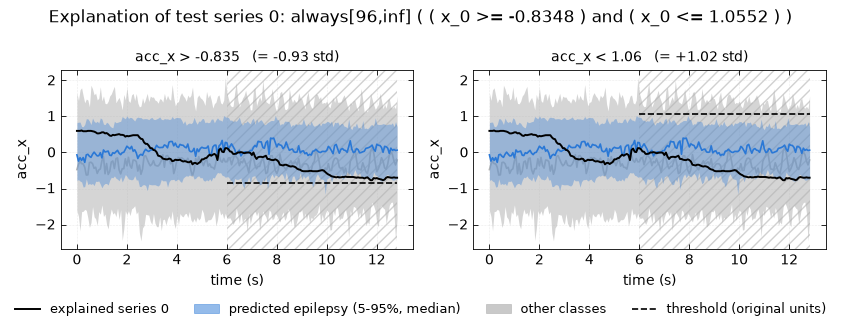

In [8]:
def draw_atoms(phi, k, ax_row, highlight=None):
    for ax, (a, t0, t1, _) in zip(ax_row, atom_spans(phi)):
        v = a.var_index
        t1 = T - 1 if t1 is None else min(t1, T - 1)
        own = pred["test"] == k
        # each group as its 5-95% band over the series at every time step, and its median
        for series, color, alpha, z in ((X_raw["test"][~own, v], OTHER, 0.55, 1),
                                        (X_raw["test"][own, v], CLASS_COLORS[k], 0.35, 2)):
            lo, med, hi = np.percentile(series, [5, 50, 95], axis=0)
            ax.fill_between(t_sec, lo, hi, color=color, alpha=alpha, lw=0, zorder=z)
            ax.plot(t_sec, med, color=color, lw=1.2, zorder=z + 0.5)
        if highlight is not None:
            ax.plot(t_sec, X_raw["test"][highlight, v], color=INK, lw=1.4, zorder=4)
        thr = atom_threshold(a, mean, std)
        ax.axvspan(t0 / info.hz, t1 / info.hz, facecolor="none", edgecolor=INK_2, hatch="///", lw=0, alpha=0.25, zorder=0)
        ax.hlines(thr, t0 / info.hz, t1 / info.hz, color=INK, ls="--", lw=1.2, zorder=5)
        ax.set_title(f"{info.var_names[v]} {'<' if a.lte else '>'} {thr:.3g}   "
                     f"(= {a.threshold:+.2f} std)", color=INK)
        ax.set_ylabel(info.var_names[v]); ax.set_xlabel("time (s)")
        style_axis(ax)

spans = atom_spans(phi)
fig, axes = plt.subplots(1, len(spans), figsize=(4.2 * len(spans), 3), squeeze=False)
draw_atoms(phi, k, axes[0], highlight=i)
from matplotlib.patches import Patch
handles = [plt.Line2D([], [], color=INK, lw=1.4, label=f"explained series {i}"),
           Patch(color=CLASS_COLORS[k], alpha=0.5, label=f"predicted {classes[k]} (5-95%, median)"),
           Patch(color=OTHER, alpha=0.7, label="other classes"),
           plt.Line2D([], [], color=INK, ls="--", label="threshold (original units)")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Explanation of test series {i}: {phi_orig}", color=INK)
plt.tight_layout()

## 6. Instance explanations of the whole test set

For every test series: the explanation is built against the train series, then evaluated on the **test** series (the explained one left out). Precision: fraction of the test series satisfying the explanation that are predicted as the same class. Recall: fraction of the test series predicted as that class that satisfy it (the coverage of the paper).

In [9]:
test_rules = ir.explain_instances(F_te, W, F_tr, pred["train"], rcfg)
rows = []
for i_, rr in enumerate(test_rules):
    if not rr["literals"]:
        continue
    m = ir.rule_metrics(ir.covered(rr["literals"], F_te), rr["k"], pred["test"], exclude=i_)
    phi_s = ir.rule_formula(rr["literals"], formulas, sigma, X_tr)
    rows.append({"class": classes[rr["k"]], "precision": m["precision"], "recall": m["coverage"],
                 "tp": m["tp"], "support": m["support"], "literals": len(rr["literals"]),
                 "nodes": F0.formula_size(phi_s)})
inst = pd.DataFrame(rows)
print(f"{len(inst)} of {len(test_rules)} test series explained; pooled precision {inst.tp.sum() / inst.support.sum():.3f}\n")
summary = inst.groupby("class")[["precision", "recall", "literals", "nodes"]].mean()
summary.loc["all"] = inst[["precision", "recall", "literals", "nodes"]].mean()
summary.round(3)

138 of 138 test series explained; pooled precision 0.948



,precision,recall,literals,nodes
class,,,,
epilepsy,0.846,0.522,1.500,6.588
running,1.000,0.695,1.324,6.946
sawing,0.959,0.471,2.161,7.935
walking,0.935,0.608,1.167,5.417
all,0.936,0.579,1.514,6.681


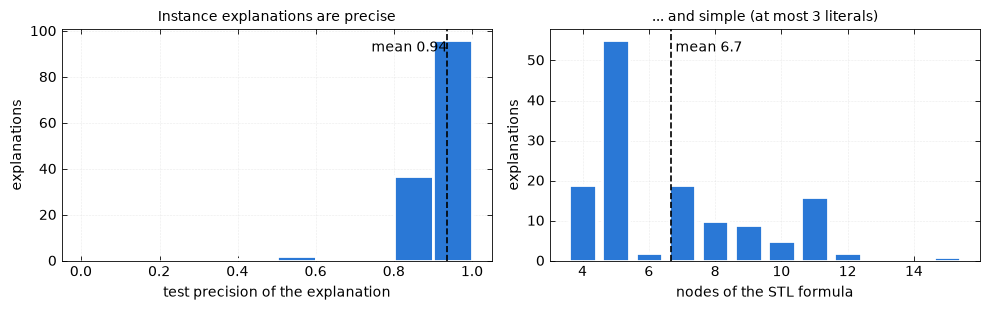

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
p = inst.precision.dropna()
a1.hist(p, bins=np.linspace(0, 1, 11), color=CLASS_COLORS[0], edgecolor="white", linewidth=2)
a1.axvline(p.mean(), color=INK, ls="--", lw=1.2)
a1.text(p.mean(), a1.get_ylim()[1] * 0.95, f" mean {p.mean():.2f}", color=INK, ha="right", va="top")
a1.set_xlabel("test precision of the explanation"); a1.set_ylabel("explanations")
a1.set_title("Instance explanations are precise", color=INK)
sizes = inst.nodes.value_counts().sort_index()
a2.bar(sizes.index, sizes.values, width=0.8, color=CLASS_COLORS[0], edgecolor="white", linewidth=2)
a2.axvline(inst.nodes.mean(), color=INK, ls="--", lw=1.2)
a2.text(inst.nodes.mean(), a2.get_ylim()[1] * 0.95, f" mean {inst.nodes.mean():.1f}", color=INK, va="top")
a2.set_xlabel("nodes of the STL formula"); a2.set_ylabel("explanations")
a2.set_title(f"... and simple (at most {rcfg.n_max} literals)", color=INK)
for ax in (a1, a2):
    style_axis(ax)
plt.tight_layout()

## 7. Global explanations

1. Instance explanations of every train series, each left out of its own counts.
2. For each class $k$: rules are made distinct by the train series that satisfy them; a greedy cover adds the rule covering the most train series predicted as $k$ not yet covered, and stops when the best one adds fewer than $\max(1, \lceil 0.05\,|P_k|\rceil)$.
3. Each selected rule becomes its STL formula, simplified; $\mathcal{G}(k)$ is their disjunction.

The table reports, on the **test** series, the precision, recall and $F_1$ of each $\mathcal{G}(k)$ and its size (nodes of the whole disjunction).

In [11]:
train_rules = ir.explain_instances(F_tr, W, F_tr, pred["train"], rcfg, train=True)
G = ir.global_explanations(train_rules, F_tr, X_tr, pred["train"], formulas, sigma, rcfg)

def sat_or(phis, Xs):
    return np.any([eval_robustness(p, Xs) > 0 for p in phis], axis=0) if phis else np.zeros(len(Xs), bool)

rows, SAT = [], np.zeros((K, len(X_te)), bool)
for kk in range(K):
    phis = G.get(kk, [])
    SAT[kk] = sat_or(phis, X_te)
    assert (SAT[kk] == sat_or([to_original_units(p, mean, std) for p in phis], X_raw["test"])).all()
    m = ir.rule_metrics(SAT[kk], kk, pred["test"])
    rows.append({"class": classes[kk], "disjuncts": len(phis),
                 "nodes": sum(F0.formula_size(p) for p in phis) + max(len(phis) - 1, 0),
                 "precision": m["precision"], "recall": m["coverage"],
                 "F1": 2 * m["tp"] / (m["support"] + m["tp"] / m["coverage"]) if m["tp"] else 0.0})
glob = pd.DataFrame(rows).set_index("class")
glob.loc["mean"] = glob.mean()
glob.round(3)

,disjuncts,nodes,precision,recall,F1
class,,,,,
epilepsy,3.00,34.0,0.800,0.941,0.865
running,2.00,17.0,1.000,0.865,0.928
sawing,2.00,20.0,0.900,0.581,0.706
walking,4.00,31.0,0.889,0.889,0.889
mean,2.75,25.5,0.897,0.819,0.847


**Do the global explanations separate the classes?** Left: for each $\mathcal{G}(k)$ (row), the fraction of the test series predicted as each class (column) that satisfy it; a perfect separation is the identity. Right: the robustness of $\mathcal{G}(k)$ on every test series (standardized units, the maximum over the disjuncts): positive means satisfied.

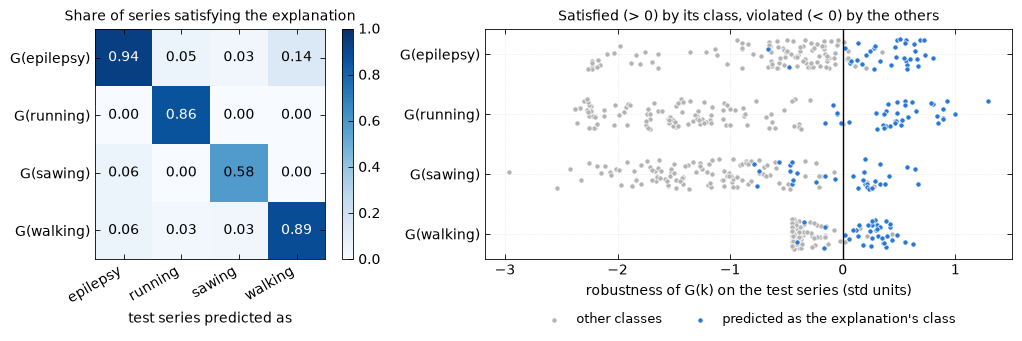

In [12]:
P = np.array([[SAT[kk][pred["test"] == l].mean() if (pred["test"] == l).any() else np.nan for l in range(K)]
              for kk in range(K)])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
im = a1.imshow(P, cmap="Blues", vmin=0, vmax=1)
for kk in range(K):
    for l in range(K):
        a1.text(l, kk, f"{P[kk, l]:.2f}", ha="center", va="center", color="white" if P[kk, l] > 0.6 else INK)
a1.set_xticks(range(K), classes, rotation=30, ha="right"); a1.set_yticks(range(K), [f"G({c})" for c in classes])
a1.set_xlabel("test series predicted as"); a1.set_title("Share of series satisfying the explanation", color=INK)
fig.colorbar(im, ax=a1, fraction=0.046)

rng = np.random.default_rng(0)
for kk in range(K):
    rho = np.max([eval_robustness(p, X_te) for p in G[kk]], axis=0) if G.get(kk) else np.full(len(X_te), np.nan)
    own = pred["test"] == kk
    yj = kk + rng.uniform(-0.25, 0.25, len(rho))
    a2.scatter(rho[~own], yj[~own], s=14, color=OTHER, edgecolor="white", linewidth=0.5, label="other classes" if kk == 0 else None)
    a2.scatter(rho[own], yj[own], s=14, color=CLASS_COLORS[0], edgecolor="white", linewidth=0.5,
               label="predicted as the explanation's class" if kk == 0 else None)
a2.axvline(0, color=INK, lw=1)
a2.set_yticks(range(K), [f"G({c})" for c in classes]); a2.invert_yaxis()
a2.set_xlabel("robustness of G(k) on the test series (std units)")
a2.set_title("Satisfied (> 0) by its class, violated (< 0) by the others", color=INK)
a2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
style_axis(a2)
plt.tight_layout()

**Global explanations in original units.** For each class, the first (broadest) disjunct of $\mathcal{G}(k)$, its atoms drawn on the raw test series. The thresholds are those of the STL formula in original units printed below. For an atom under two nested temporal operators the shaded span is every time it can be read, not a window the series must stay in.

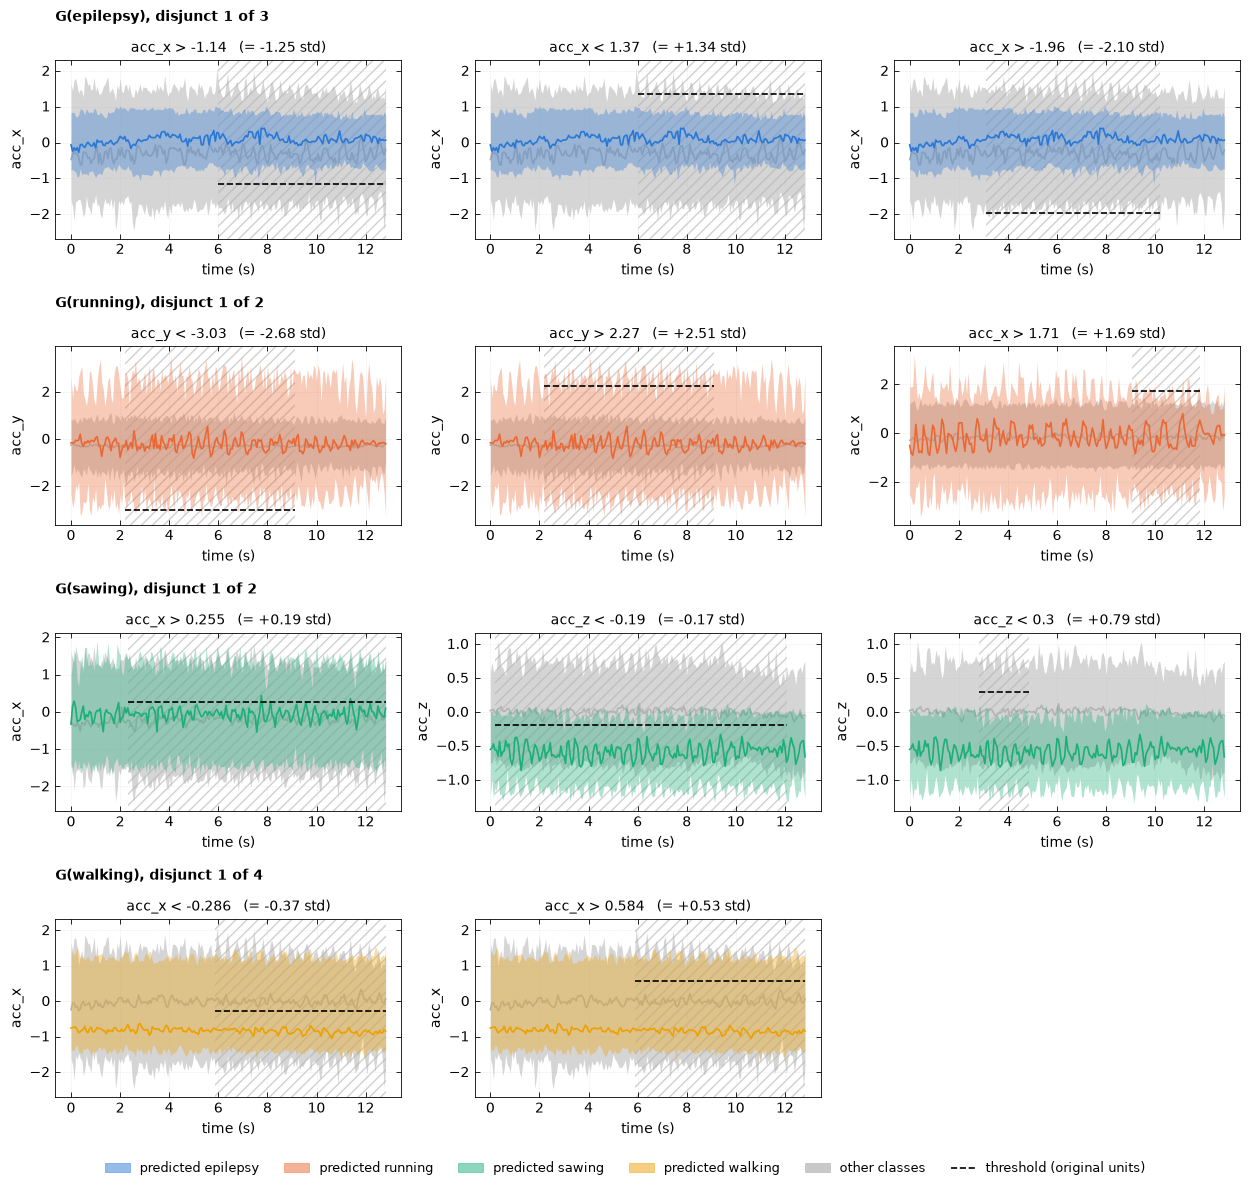

In [13]:
n_cols = max(min(len(atom_spans(G[kk][0])), 3) for kk in G)
fig, axes = plt.subplots(K, n_cols, figsize=(4.2 * n_cols, 2.9 * K), squeeze=False)
for kk in range(K):
    for ax in axes[kk]:
        ax.set_visible(False)
    if not G.get(kk):
        continue
    first = G[kk][0]
    used = axes[kk][:min(len(atom_spans(first)), n_cols)]
    for ax in used:
        ax.set_visible(True)
    draw_atoms(first, kk, used)
    used[0].annotate(f"G({classes[kk]}), disjunct 1 of {len(G[kk])}", (0, 1.22), xycoords="axes fraction",
                     fontweight="bold", color=INK)
handles = [Patch(color=CLASS_COLORS[kk], alpha=0.5, label=f"predicted {classes[kk]}") for kk in range(K)]
handles += [Patch(color=OTHER, alpha=0.7, label="other classes"),
            plt.Line2D([], [], color=INK, ls="--", label="threshold (original units)")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout()

In [14]:
for kk, phis in sorted(G.items()):
    print(f"G({classes[kk]}):")
    for p in phis:
        print("   ", to_original_units(nnf(p), mean, std))

G(epilepsy):
    ( always[96,inf] ( ( x_0 >= -1.1446 ) and ( x_0 <= 1.365 ) ) ) and ( ( always[50,163] ( x_0 >= -1.9591 ) ) and ( always[187,inf] ( x_0 <= 0.965 ) ) )
    ( ( always[96,inf] ( ( x_0 >= -1.1796 ) and ( x_0 <= 1.4 ) ) ) and ( eventually[94,inf] ( x_0 >= -0.0022 ) ) ) and ( ( eventually[0,inf] ( x_1 >= 0.7322 ) ) and ( eventually[16,202] ( x_1 <= -0.91 ) ) )
    ( ( always[50,163] ( x_0 >= -1.432 ) ) and ( always[187,inf] ( x_0 <= 0.438 ) ) ) and ( eventually ( x_2 <= -0.5198 ) )
G(running):
    ( eventually[35,146] ( ( x_1 <= -3.025 ) or ( x_1 >= 2.2712 ) ) ) and ( ( eventually[145,189] ( x_0 >= 1.711 ) ) or ( eventually[119,128] ( x_0 <= -1.37 ) ) )
    eventually[35,146] ( ( x_1 <= -3.44 ) or ( x_1 >= 2.6862 ) )
G(sawing):
    ( ( always ( eventually[37,41] ( x_0 >= 0.255 ) ) ) and ( always[3,190] ( eventually[0,3] ( x_2 <= -0.19 ) ) ) ) and ( always[45,78] ( x_2 <= 0.3 ) )
    ( eventually[30,31] ( x_2 <= -0.89 ) ) and ( always[23,70] ( eventually[62,64] ( x_2 <= -0.23